<a href="https://colab.research.google.com/github/gonmpa/Notebook_Jupyter_Mineria_Datos_Supervisado_Clasificacion/blob/main/Evaluacion_Final_MD_Pino_Gonzalo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 0. Portada: Predicción de Tramos de Carrera Docente (Evaluación Docente 2024)

| Campo | Detalle |
| :--- | :--- |
| **Asignatura** | Minería de Datos (`IEI097`) |
| **Proyecto** | Implementación CRISP-DM: Clasificación de Tramos de Carrera Docente (`PF_CAT_CARRERA`) |
| **Integrantes** | Gonzalo Matías Pino Araya  |
| **Grupo 00 / Experimento MLflow** | `IEI097-G00`  |
| **Repositorio GitHub** | [https://github.com/gonmpa/Notebook_Jupyter_Mineria_Datos_Supervisado_Clasificacion](https://github.com/gonmpa/Notebook_Jupyter_Mineria_Datos_Supervisado_Clasificacion/tree/main) |
| **Informe CRISP-DM (Act. 2.13)** | [https://github.com/gonmpa/Notebook_Jupyter_Mineria_Datos_Supervisado_Clasificacion/blob/main/IEI097_Informe_G00.pdf](https://github.com/gonmpa/Notebook_Jupyter_Mineria_Datos_Supervisado_Clasificacion/blob/main/IEI097_Informe_G00.pdf) |

### Resumen del Problema de Negocio
El Sistema de Desarrollo Profesional Docente en Chile clasifica a los profesores evaluados en cinco tramos (`A`, `B`, `C`, `D`, `E`) según su desempeño. El objetivo de este proyecto es construir y evaluar modelos de aprendizaje supervisado capaces de predecir el tramo asignado (`PF_CAT_CARRERA`) a partir de variables sociodemográficas, laborales y del establecimiento educacional, contrastando los resultados con las hipótesis formuladas en la fase de planificación CRISP-DM.

## 1. Carga de Datos

Para garantizar la reproducibilidad completa del notebook sin intervención manual (evitando el uso de `files.upload()`), el conjunto de datos oficial del Ministerio de Educación (`20251118_EVALUACION_DOCENTE_2024_20251118_PUBL.csv`) se descarga directamente desde su fuente alojada en repositorio público.

In [1]:
# [C-1.1] Importación de librerías base y configuración visual
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración general de gráficos
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


In [2]:
# [C-1.2] Búsqueda automática y carga reproducible del CSV desde GitHub
import requests

USUARIO = "gonmpa"
REPO = "Notebook_Jupyter_Mineria_Datos_Supervisado_Clasificacion"
RAMA = "main"

api_url = f"https://api.github.com/repos/{USUARIO}/{REPO}/git/trees/{RAMA}?recursive=1"
respuesta = requests.get(api_url).json()

archivos_csv = [
    item["path"] for item in respuesta.get("tree", [])
    if item["path"].lower().endswith(".csv")
]

print("Archivos CSV encontrados en el repositorio:", archivos_csv)

if archivos_csv:
    URL_DATASET = f"https://raw.githubusercontent.com/{USUARIO}/{REPO}/{RAMA}/{archivos_csv[0]}"
    try:
        df = pd.read_csv(URL_DATASET, sep=";", encoding="utf-8-sig", low_memory=False)
    except UnicodeDecodeError:
        df = pd.read_csv(URL_DATASET, sep=";", encoding="latin1", low_memory=False)
    print(f"Dataset cargado exitosamente desde: {URL_DATASET}")
    print(f"Dimensiones: {df.shape[0]:,} filas y {df.shape[1]} columnas.")
else:
    print("No hay ningún archivo .csv subido aún en el repositorio de GitHub.")

Archivos CSV encontrados en el repositorio: ['20251118_EVALUACION_DOCENTE_2024_20251118_PUBL.csv']
Dataset cargado exitosamente desde: https://raw.githubusercontent.com/gonmpa/Notebook_Jupyter_Mineria_Datos_Supervisado_Clasificacion/main/20251118_EVALUACION_DOCENTE_2024_20251118_PUBL.csv
Dimensiones: 25,197 filas y 22 columnas.


### 1.1 Inspección Inicial de Dimensiones y Tipos de Datos

A continuación se verifican las dimensiones del dataset (filas y columnas), los tipos de datos inferidos por `pandas` y una muestra inicial de los registros.

In [3]:
# [C-1.3] Inspección de dimensiones, listado de columnas, tipos de datos y primeras filas
print("=== DIMENSIONES DEL DATASET ===")
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}\n")

print("=== NOMBRES DE COLUMNAS ===")
print(df.columns.tolist(), "\n")

print("=== INFORMACIÓN Y TIPOS DE DATOS ===")
df.info()

print("\n=== PRIMERAS 5 FILAS ===")
display(df.head())

=== DIMENSIONES DEL DATASET ===
Filas: 25197 | Columnas: 22

=== NOMBRES DE COLUMNAS ===
['AGNO_EVAL', 'RBD', 'DGV_RBD', 'NOM_RBD', 'COD_REG_RBD', 'NOM_REG_RBD_A', 'COD_PRO_RBD', 'COD_COM_RBD', 'NOM_COM_RBD', 'COD_DEPROV_RBD', 'NOM_DEPROV_RBD', 'COD_DEPE', 'COD_DEPE2', 'RURAL_RBD', 'ESTADO_ESTAB', 'MRUN', 'DOC_GENERO', 'DOC_FEC_NAC', 'NIVEL', 'PF_PJE', 'PF_ESC', 'PF_CAT_CARRERA'] 

=== INFORMACIÓN Y TIPOS DE DATOS ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25197 entries, 0 to 25196
Data columns (total 22 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   AGNO_EVAL       25197 non-null  int64  
 1   RBD             25197 non-null  int64  
 2   DGV_RBD         25197 non-null  int64  
 3   NOM_RBD         25197 non-null  object 
 4   COD_REG_RBD     25197 non-null  int64  
 5   NOM_REG_RBD_A   25197 non-null  object 
 6   COD_PRO_RBD     25197 non-null  int64  
 7   COD_COM_RBD     25197 non-null  int64  
 8   NOM_COM_RBD   

,AGNO_EVAL,RBD,DGV_RBD,NOM_RBD,COD_REG_RBD,NOM_REG_RBD_A,COD_PRO_RBD,COD_COM_RBD,NOM_COM_RBD,COD_DEPROV_RBD,...,COD_DEPE2,RURAL_RBD,ESTADO_ESTAB,MRUN,DOC_GENERO,DOC_FEC_NAC,NIVEL,PF_PJE,PF_ESC,PF_CAT_CARRERA
0,2024,1,9,LICEO POLITECNICO ARICA,15,AYP,151,15101,ARICA,151,...,5,0,1,5205805,2,197105,EMTP,"2,64",NaN,B
1,2024,1,9,LICEO POLITECNICO ARICA,15,AYP,151,15101,ARICA,151,...,5,0,1,6586929,2,197906,EM,"2,71",NaN,B
2,2024,1,9,LICEO POLITECNICO ARICA,15,AYP,151,15101,ARICA,151,...,5,0,1,19890672,1,198004,EM,"2,17",NaN,D
3,2024,1,9,LICEO POLITECNICO ARICA,15,AYP,151,15101,ARICA,151,...,5,0,1,5559172,1,198112,EM,"2,53",NaN,B
4,2024,1,9,LICEO POLITECNICO ARICA,15,AYP,151,15101,ARICA,151,...,5,0,1,11230387,2,198109,EMTP,"2,54",NaN,B


#### Interpretación 1.1 — Estructura Inicial del Dataset
* **Dimensiones:** El conjunto de datos cuenta con `25.197` registros (docentes evaluados en el proceso 2024) y `22` variables.
* **Tipos de datos:** Se identifican variables numéricas enteras (códigos territoriales, bienios de experiencia, fechas en formato `AAAAMM`), variables decimales (puntaje de portafolio) y variables categóricas de texto (tramo de carrera, dependencia, ruralidad).
* **Observación preliminar:** Se verifica que la columna `PF_ESC` tiene Se verifica que la columna PF_ESC no contiene datos válidos (25.197 valores nulos; 100% vacía), `AGNO_EVAL` es constante (`2024`), `DOC_FEC_NAC` almacena fechas en formato entero `AAAAMM` y `PF_PJE` figura como tipo `object` debido al uso de coma decimal (`2,64`). Además, existen pares de columnas redundantes que repiten información territorial en código y texto (por ejemplo, `COD_REG_RBD` y `NOM_REG_RBD_A`).

## 2. Análisis Exploratorio de Datos (EDA)

En esta fase se examina la calidad, distribución y relación entre las variables del dataset con el propósito de fundamentar técnicamente cada decisión de limpieza y transformación en el `Pipeline` de preparación.

### 2.1 Estadísticos Descriptivos
Se calculan las medidas de tendencia central, dispersión y cuartiles para las variables numéricas, así como el conteo de categorías únicas y frecuencias modales para las variables categóricas.

In [4]:
# [C-2.1] Estadísticos descriptivos de variables numéricas y categóricas
# Creamos una copia temporal para calcular EDAD y PF_PJE numérico solo con fines exploratorios
df_eda = df.copy()
df_eda["PF_PJE_NUM"] = pd.to_numeric(df_eda["PF_PJE"].astype(str).str.replace(",", "."), errors="coerce")
df_eda["EDAD_TEMP"] = np.where(
    df_eda["DOC_FEC_NAC"] == 190001,
    np.nan,
    2024 - (df_eda["DOC_FEC_NAC"] // 100)
)

print("=== ESTADÍSTICOS DESCRIPTIVOS: VARIABLES NUMÉRICAS RELEVANTES ===")
cols_num_eda = ["EDAD_TEMP", "PF_PJE_NUM", "COD_REG_RBD", "COD_DEPE", "COD_DEPE2", "RURAL_RBD", "ESTADO_ESTAB", "DOC_GENERO"]
display(df_eda[cols_num_eda].describe().T.round(2))

print("\n=== ESTADÍSTICOS DESCRIPTIVOS: VARIABLES CATEGÓRICAS ===")
cols_cat_eda = ["PF_CAT_CARRERA", "NIVEL", "NOM_REG_RBD_A"]
display(df_eda[cols_cat_eda].describe().T)

=== ESTADÍSTICOS DESCRIPTIVOS: VARIABLES NUMÉRICAS RELEVANTES ===


,count,mean,std,min,25%,50%,75%,max
EDAD_TEMP,25195.0,41.46,8.95,25.0,35.0,40.00,47.00,78.0
PF_PJE_NUM,25197.0,2.51,0.34,1.0,2.3,2.52,2.73,4.0
COD_REG_RBD,25197.0,9.41,3.88,1.0,6.0,9.00,13.00,16.0
COD_DEPE,25197.0,3.11,1.74,1.0,2.0,3.00,3.00,8.0
COD_DEPE2,25197.0,2.33,1.50,1.0,1.0,2.00,2.00,7.0
RURAL_RBD,25197.0,0.13,0.34,0.0,0.0,0.00,0.00,1.0
ESTADO_ESTAB,25197.0,1.14,0.63,1.0,1.0,1.00,1.00,4.0
DOC_GENERO,25197.0,1.75,0.44,1.0,1.0,2.00,2.00,2.0



=== ESTADÍSTICOS DESCRIPTIVOS: VARIABLES CATEGÓRICAS ===


,count,unique,top,freq
PF_CAT_CARRERA,25197,5,B,11446
NIVEL,25197,11,EB,6799
NOM_REG_RBD_A,25197,16,RM,7962


#### Interpretación 2.1 — Estadísticos Descriptivos
* **Variables numéricas:** La edad docente (`EDAD_TEMP`, calculada sobre `25.195` registros válidos tras excluir `2` casos con centinela `190001`) presenta una media de `41,46` años (`DE = 8,95`), una mediana de `40,0` años y un rango entre `25` y `78` años. El puntaje de portafolio (`PF_PJE_NUM`) tiene una media de `2,51` (`DE = 0,34`) y mediana de `2,52` (rango `1,00` a `4,00`). Respecto al contexto escolar, solo el `13%` de las evaluaciones corresponde a establecimientos rurales (`RURAL_RBD`, media `0,13`) y predomina el género femenino (`DOC_GENERO`, media `1,75`, equivalente a un `75%` de mujeres considerando código `1=Hombre` y `2=Mujer`).
* **Variables categóricas:** En la variable objetivo `PF_CAT_CARRERA` existen `5` categorías únicas, siendo el tramo **`B`** el más frecuente con `11.446` docentes (`45,43%` del total). En `NIVEL` (`11` modalidades) predomina Educación Básica (`EB`) con `6.799` casos (`26,98%`), y a nivel territorial (`16` regiones) la Región Metropolitana (`RM`) concentra `7.962` evaluaciones (`31,60%`).

### 2.2 Calidad de Datos: Valores Nulos, Duplicados y Centinelas
Se audita la presencia de registros duplicados, el porcentaje de valores faltantes (`NaN`) por columna y la existencia de valores centinela codificados en el diccionario del Mineduc (como `190001` en fecha de nacimiento).

In [5]:
# [C-2.2] Auditoría de valores nulos, filas duplicadas y valores centinela
print("=== DUPLICADOS ===")
print(f"Filas completamente duplicadas: {df.duplicated().sum()}")
print(f"Docentes (MRUN) repetidos: {df['MRUN'].duplicated().sum()}\n")

print("=== PORCENTAJE DE VALORES NULOS POR COLUMNA ===")
nulos = pd.DataFrame({
    "Nulos": df.isnull().sum(),
    "Porcentaje (%)": (df.isnull().sum() / len(df) * 100).round(2)
})
display(nulos[nulos["Nulos"] > 0] if (nulos["Nulos"] > 0).any() else nulos.tail(5))

print("\n=== AUDITORÍA DE CENTINELAS Y VALORES ESPECIALES ===")
print(f"Registros con DOC_FEC_NAC == 190001 (centinela): {(df['DOC_FEC_NAC'] == 190001).sum()}")
print("Valores únicos en PF_CAT_CARRERA:", df["PF_CAT_CARRERA"].value_counts(dropna=False).to_dict())
print("Valores únicos en NIVEL:", df["NIVEL"].value_counts(dropna=False).to_dict())

=== DUPLICADOS ===
Filas completamente duplicadas: 0
Docentes (MRUN) repetidos: 0

=== PORCENTAJE DE VALORES NULOS POR COLUMNA ===


,Nulos,Porcentaje (%)
PF_ESC,25197,100.0



=== AUDITORÍA DE CENTINELAS Y VALORES ESPECIALES ===
Registros con DOC_FEC_NAC == 190001 (centinela): 2
Valores únicos en PF_CAT_CARRERA: {'B': 11446, 'C': 6970, 'D': 3587, 'A': 1613, 'E': 1581}
Valores únicos en NIVEL: {'EB': 6799, 'EM': 6479, 'NEET': 3488, 'EP': 3215, 'PC': 2855, 'NEEP': 1228, 'EMTP': 665, 'EA': 303, 'ECE': 72, 'SLI': 65, 'PH': 28}


#### Interpretación 2.2 — Diagnóstico de Calidad de Datos
* **Duplicados:** Se confirma integridad a nivel de registro: existen `0` filas duplicadas y `0` identificadores docentes (`MRUN`) repetidos, por lo que cada fila representa una evaluación única.
* **Valores nulos:** Únicamente la columna `PF_ESC` presenta valores faltantes (`25.197` registros, equivalente al `100,0%` del dataset), por lo que será eliminada en la fase de preparación. La variable objetivo `PF_CAT_CARRERA` no tiene registros nulos ni códigos inválidos (`100%` distribuido limpiamente entre las categorías `A`, `B`, `C`, `D` y `E`).
* **Valores centinela:** En `DOC_FEC_NAC` se detectan exactamente `2` registros con el valor centinela `190001`. Al derivar la variable `EDAD`, estos dos casos se transformarán en `NaN` y se imputarán con la mediana dentro del `Pipeline` de entrenamiento.

### 2.3 Distribución de la Variable Objetivo (`PF_CAT_CARRERA`)
Al tratarse de un problema de clasificación multiclase, se analiza la frecuencia absoluta y porcentual de cada tramo de carrera docente (`A`, `B`, `C`, `D`, `E`) para evaluar el grado de desbalanceo de clases.

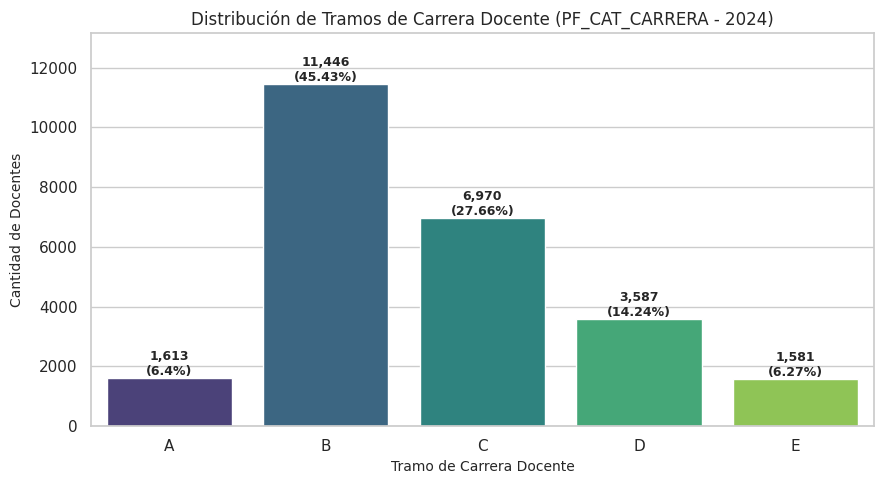

In [6]:
# [C-2.3] Distribución de la variable objetivo PF_CAT_CARRERA
orden_tramos = sorted(df["PF_CAT_CARRERA"].dropna().unique())
conteo_tramos = df["PF_CAT_CARRERA"].value_counts().reindex(orden_tramos)
porc_tramos = (conteo_tramos / len(df) * 100).round(2)

fig, ax = plt.subplots(figsize=(9, 5))
bars = sns.barplot(x=conteo_tramos.index, y=conteo_tramos.values, palette="viridis", ax=ax)

for bar, pct in zip(bars.patches, porc_tramos.values):
    ax.annotate(
        f"{int(bar.get_height()):,}\n({pct}%)",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center", va="bottom", fontsize=9, fontweight="bold"
    )

ax.set_title("Distribución de Tramos de Carrera Docente (PF_CAT_CARRERA - 2024)")
ax.set_xlabel("Tramo de Carrera Docente")
ax.set_ylabel("Cantidad de Docentes")
ax.set_ylim(0, conteo_tramos.max() * 1.15)
plt.tight_layout()
plt.show()

#### Interpretación 2.3 — Distribución de la Variable Objetivo
* **Desbalanceo de clases:** Se evidencia una fuerte asimetría entre los cinco tramos de carrera docente: las categorías intermedias **`B`** (`11.446` docentes; `45,43%`) y **`C`** (`6.970` docentes; `27,66%`) concentran en conjunto el **`73,09%`** de la muestra, seguidas por **`D`** (`3.587`; `14,24%`). En contraste, los tramos extremos **`A`** (`1.613`; `6,40%`) y **`E`** (`1.581`; `6,27%`) representan una proporción minoritaria (una razón aproximada de `7,2 : 1` respecto a la clase mayoritaria `B`)[cite: 5].
* **Impacto en el modelado:** Este desbalanceo implica que un modelo ingenuo que prediga siempre la clase `B` obtendría un `45,43%` de *Accuracy* sin aprender patrones reales[cite: 5]. Por ello, se aplicará **partición estratificada** (`stratify=y`), ponderación balanceada (`class_weight='balanced'`) en los algoritmos y se priorizará **`F1-Score Macro`** como métrica principal de comparación.

### 2.4 Distribuciones de Variables Predictoras (Numéricas y Categóricas)
Se visualizan histogramas para las variables numéricas clave y gráficos de frecuencia para las variables categóricas relevantes del contexto laboral docente.

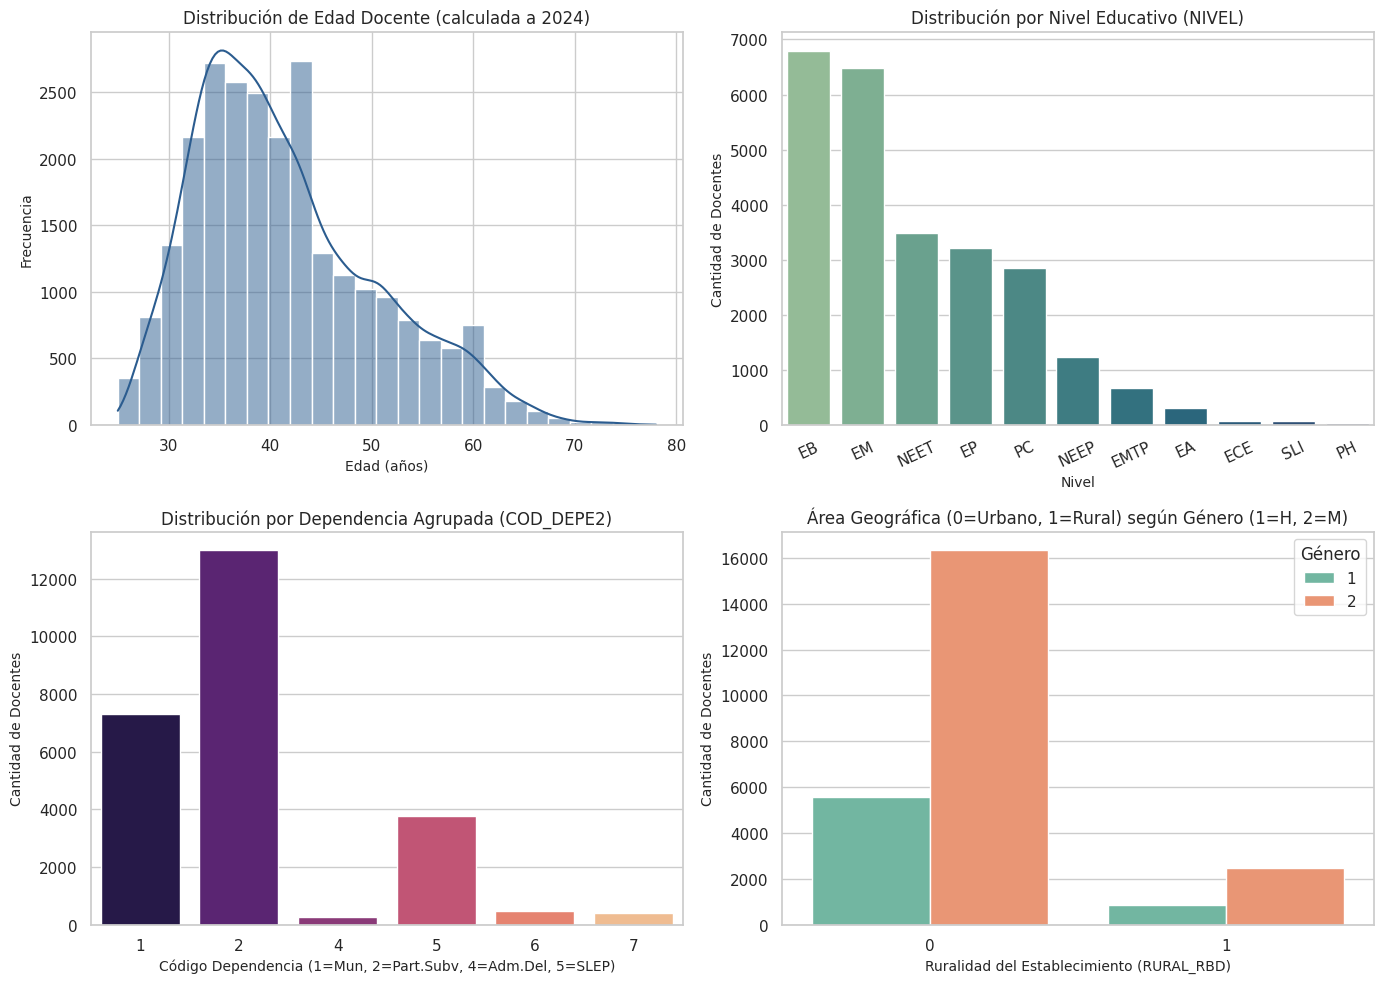

In [7]:
# [C-2.4] Distribuciones de variables predictoras clave
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histograma de Edad (sin centinela 190001)
sns.histplot(df_eda["EDAD_TEMP"].dropna(), bins=25, kde=True, color="#2b5c8f", ax=axes[0, 0])
axes[0, 0].set_title("Distribución de Edad Docente (calculada a 2024)")
axes[0, 0].set_xlabel("Edad (años)")
axes[0, 0].set_ylabel("Frecuencia")

# 2. Distribución por Nivel de Enseñanza (NIVEL)
orden_nivel = df["NIVEL"].value_counts().index
sns.countplot(data=df, x="NIVEL", order=orden_nivel, palette="crest", ax=axes[0, 1])
axes[0, 1].set_title("Distribución por Nivel Educativo (NIVEL)")
axes[0, 1].set_xlabel("Nivel")
axes[0, 1].set_ylabel("Cantidad de Docentes")
axes[0, 1].tick_params(axis="x", rotation=25)

# 3. Distribución por Dependencia Administrativa Agrupada (COD_DEPE2)
sns.countplot(data=df, x="COD_DEPE2", palette="magma", ax=axes[1, 0])
axes[1, 0].set_title("Distribución por Dependencia Agrupada (COD_DEPE2)")
axes[1, 0].set_xlabel("Código Dependencia (1=Mun, 2=Part.Subv, 4=Adm.Del, 5=SLEP)")
axes[1, 0].set_ylabel("Cantidad de Docentes")

# 4. Distribución por Área Geográfica (RURAL_RBD) y Género (DOC_GENERO)
sns.countplot(data=df, x="RURAL_RBD", hue="DOC_GENERO", palette="Set2", ax=axes[1, 1])
axes[1, 1].set_title("Área Geográfica (0=Urbano, 1=Rural) según Género (1=H, 2=M)")
axes[1, 1].set_xlabel("Ruralidad del Establecimiento (RURAL_RBD)")
axes[1, 1].set_ylabel("Cantidad de Docentes")
axes[1, 1].legend(title="Género")

plt.tight_layout()
plt.show()

#### Interpretación 2.4 — Distribuciones de Predictoras
* **Asimetrías y sesgos:** La variable derivada `EDAD_TEMP` muestra una distribución unimodal con **sesgo positivo (cola hacia la derecha)**, concentrando la mayor densidad de docentes entre los `33` y `44` años y descendiendo progresivamente hacia edades mayores (`60` a `78` años). Esta asimetría justifica aplicar `StandardScaler` para centrar y estandarizar su escala antes de entrenar la Regresión Logística.
* **Concentración categórica:** En `NIVEL`, Educación Básica (`EB`) y Educación Media (`EM`) lideran ampliamente seguidas por Educación Especial (`NEET`) y Parvularia (`EP`), mientras que modalidades como `ECE`, `SLI` y `PH` tienen baja frecuencia (por lo que `OneHotEncoder(handle_unknown="ignore")` es indispensable para evitar errores en validación cruzada). En dependencia administrativa (`COD_DEPE2`), los establecimientos Particulares Subvencionados (`2`) y Municipales (`1`) concentran la mayoría de los casos, seguidos por los Servicios Locales de Educación Pública (`5`). Finalmente, el gráfico cruzado confirma el fuerte predominio urbano (`RURAL_RBD = 0`) y femenino (`DOC_GENERO = 2`) en ambos contextos geográficos[cite: 6].

### 2.5 Detección de Valores Atípicos (*Outliers*) mediante Box-plots
Se construyen diagramas de caja (*box-plots*) sobre las variables numéricas continuas y discretas para identificar valores extremos y evaluar su coherencia con la realidad del sistema escolar chileno.

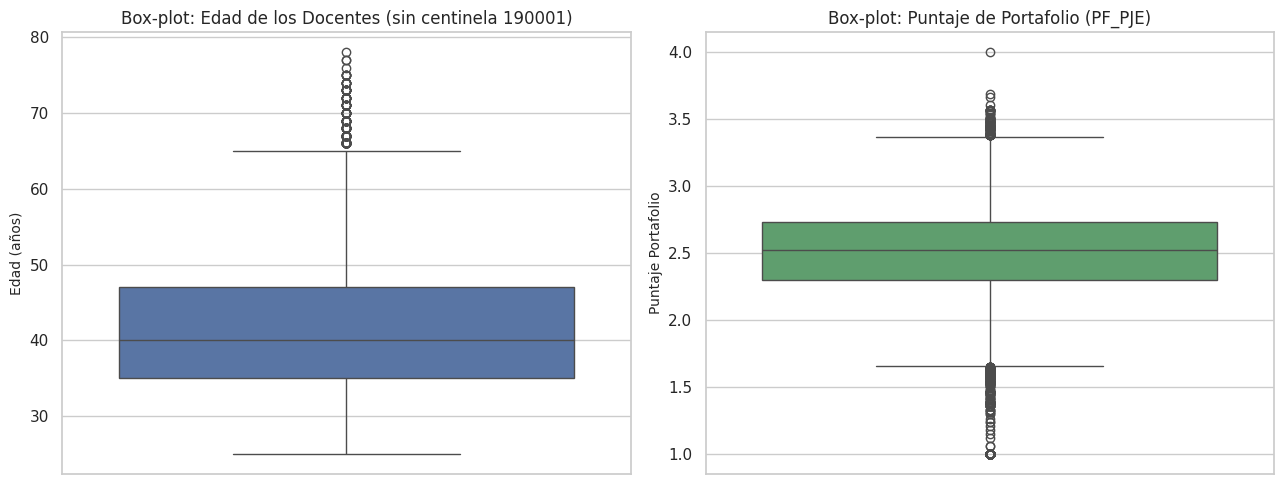

In [8]:
# [C-2.5] Detección de valores atípicos (outliers) mediante box-plots
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(y=df_eda["EDAD_TEMP"].dropna(), color="#4c72b0", ax=axes[0])
axes[0].set_title("Box-plot: Edad de los Docentes (sin centinela 190001)")
axes[0].set_ylabel("Edad (años)")

sns.boxplot(y=df_eda["PF_PJE_NUM"].dropna(), color="#55a868", ax=axes[1])
axes[1].set_title("Box-plot: Puntaje de Portafolio (PF_PJE)")
axes[1].set_ylabel("Puntaje Portafolio")

plt.tight_layout()
plt.show()

#### Interpretación 2.5 — Análisis de Outliers
* **Hallazgos en box-plots:** En `EDAD_TEMP`, el rango intercuartílico ($Q_1 = 35$ a $Q_3 = 47$ años, mediana $= 40$) ubica el bigote superior en `65` años, detectándose valores atípicos superiores entre `66` y `78` años. En `PF_PJE_NUM` (mediana $= 2,52$, $Q_1 = 2,30$, $Q_3 = 2,73$), se observan valores atípicos tanto en el extremo superior (sobre `3,37`, llegando hasta el máximo teórico `4,00`) como en el inferior (bajo `1,65`, hasta `1,00`).
* **Decisión técnica:** Todos los valores extremos observados en `EDAD_TEMP` son biológicamente y laboralmente plausibles (docentes activos cercanos o posteriores a la edad de jubilación, una vez eliminado el centinela `190001`), por lo que no se eliminan ni recortan para no perder representatividad sobre docentes con larga trayectoria; en su lugar, se mantienen aplicando `StandardScaler`. Por su parte, los *outliers* de `PF_PJE_NUM` no ingresarán al modelado debido a la exclusión completa de esta variable por fuga de datos[cite: 7].

### 2.6 Matriz de Correlaciones y Detección de Fuga de Datos (*Data Leakage*)
Se analiza la matriz de correlaciones entre variables numéricas y se examina la relación entre el puntaje de portafolio (`PF_PJE`) y la categoría asignada (`PF_CAT_CARRERA`).

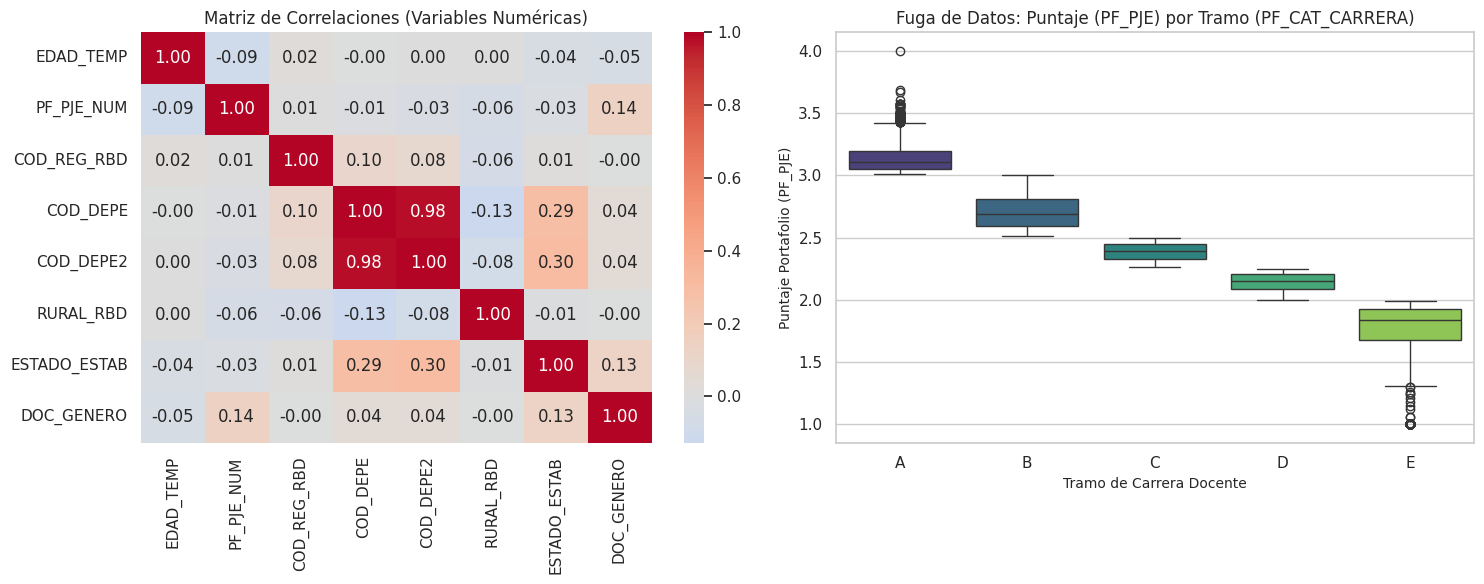

In [9]:
# [C-2.6] Matriz de correlaciones y demostración visual de fuga de datos en PF_PJE
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# 1. Heatmap de correlación entre variables numéricas
cols_corr = ["EDAD_TEMP", "PF_PJE_NUM", "COD_REG_RBD", "COD_DEPE", "COD_DEPE2", "RURAL_RBD", "ESTADO_ESTAB", "DOC_GENERO"]
corr_matrix = df_eda[cols_corr].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Matriz de Correlaciones (Variables Numéricas)")

# 2. Relación determinística PF_PJE vs PF_CAT_CARRERA (Fuga de datos)
sns.boxplot(data=df_eda, x="PF_CAT_CARRERA", y="PF_PJE_NUM", order=orden_tramos, palette="viridis", ax=axes[1])
axes[1].set_title("Fuga de Datos: Puntaje (PF_PJE) por Tramo (PF_CAT_CARRERA)")
axes[1].set_xlabel("Tramo de Carrera Docente")
axes[1].set_ylabel("Puntaje Portafolio (PF_PJE)")

plt.tight_layout()
plt.show()

#### Interpretación 2.6 — Correlaciones y Fuga de Datos (`PF_PJE`)
* **Colinealidad y fuga de datos:** El diagrama de cajas derecho confirma visualmente que los tramos de `PF_CAT_CARRERA` son particiones estrictas y sin solapamiento de `PF_PJE`: tramo `A` ($\ge 3,00$), tramo `B` ($2,50 - 2,99$), tramo `C` ($2,25 - 2,49$), tramo `D` ($2,00 - 2,24$) y tramo `E` ($< 2,00$). Incluir `PF_PJE` como predictor provocaría **fuga de datos (*data leakage*)**, generando un rendimiento artificial cercano al 100% e impidiendo evaluar el efecto real de las variables contextuales. Por ello, `PF_PJE` se excluye de la matriz $X$.
* **Correlaciones entre predictoras:** La matriz de correlaciones revela una alta multicolinealidad entre `COD_DEPE` y `COD_DEPE2` ($r = 0,98$), ya que ambos representan la dependencia administrativa del establecimiento con distinto nivel de agrupación; para evitar redundancia en la Regresión Logística, se conservará únicamente `COD_DEPE2`. El resto de las variables presenta correlaciones lineales bajas ($|r| \le 0,30$), destacando una asociación leve entre dependencia y estado del establecimiento ($r = 0,30$) y entre puntaje y género ($r = 0,14$).

### 2.7 Síntesis del EDA y Decisiones de Preparación

| Hallazgo en el EDA | Variable(s) Afectada(s) | Acción en Fase 3 (Preparación / Pipeline) |
| :--- | :--- | :--- |
| Fuga de datos determinística | `PF_PJE` | Exclusión de la matriz de características $X$. |
| 100% de valores nulos | `PF_ESC` | Eliminación de la columna. |
| Identificadores únicos y constante | `MRUN`, `RBD`, `DGV_RBD`, `NOM_RBD`, `AGNO_EVAL` | Eliminación para evitar memorización (*overfitting*) y ruido constante. |
| Redundancia texto-código | `NOM_REG_RBD_A`, `NOM_COM_RBD`, `NOM_DEPROV_RBD` | Conservar solo códigos numéricos (`COD_*`) y eliminar etiquetas de texto duplicadas. |
| Alta multicolinealidad ($r = 0,98$) | `COD_DEPE` y `COD_DEPE2` | Conservar `COD_DEPE2` (dependencia agrupada) y eliminar `COD_DEPE`. |
| Valor centinela `190001` (2 casos) | `DOC_FEC_NAC` | Cálculo de `EDAD` a 2024, reemplazo de `190001` por `NaN` e imputación por mediana en `Pipeline`. |
| Desbalanceo de clases (A–E) | `PF_CAT_CARRERA` | Partición estratificada (`stratify=y` en `train_test_split`) y `class_weight='balanced'`. |

## 3. Preparación de los Datos

Todas las transformaciones estadísticas (imputación, escalamiento y codificación *One-Hot*) se encapsulan dentro de un `Pipeline` de `scikit-learn` ajustado exclusivamente con el conjunto de entrenamiento para evitar cualquier fuga de datos hacia el conjunto de prueba.

### 3.1 Limpieza Estructural y Selección de Variables
Se aplican las reglas determinísticas previas a la partición: filtrado de registros sin categoría válida en `PF_CAT_CARRERA`, derivación de la variable `EDAD` y eliminación de columnas descartadas (`PF_PJE`, `PF_ESC`, `MRUN` y descripciones redundantes).

In [10]:
# [C-3.1] Limpieza estructural, derivación de EDAD y eliminación de variables con fuga o redundancia
df_clean = df.copy()

# Asegurar que no existan registros sin categoría objetivo válida
df_clean = df_clean.dropna(subset=["PF_CAT_CARRERA"]).copy()

# Derivar EDAD a partir de DOC_FEC_NAC (AAAAMM), convirtiendo el centinela 190001 en NaN
df_clean["EDAD"] = np.where(
    df_clean["DOC_FEC_NAC"] == 190001,
    np.nan,
    2024 - (df_clean["DOC_FEC_NAC"] // 100)
)

# Columnas descartadas según diagnóstico del EDA (Sección 2.7)
cols_eliminar = [
    "PF_PJE",                                            # Fuga de datos determinística
    "PF_ESC",                                            # 100% valores nulos
    "MRUN", "RBD", "DGV_RBD", "NOM_RBD", "AGNO_EVAL",    # Identificadores y constante
    "NOM_REG_RBD_A", "NOM_COM_RBD", "NOM_DEPROV_RBD",    # Etiquetas redundantes de texto
    "COD_DEPE",                                          # Multicolinealidad con COD_DEPE2 (r = 0.98)
    "DOC_FEC_NAC"                                        # Reemplazada por la variable derivada EDAD
]

X = df_clean.drop(columns=cols_eliminar + ["PF_CAT_CARRERA"])
y = df_clean["PF_CAT_CARRERA"]

print(f"Matriz de características X: {X.shape[0]:,} filas x {X.shape[1]} columnas")
print(f"Vector objetivo y: {y.shape[0]:,} registros")
print("\nVariables predictoras seleccionadas:")
print(X.columns.tolist())

Matriz de características X: 25,197 filas x 10 columnas
Vector objetivo y: 25,197 registros

Variables predictoras seleccionadas:
['COD_REG_RBD', 'COD_PRO_RBD', 'COD_COM_RBD', 'COD_DEPROV_RBD', 'COD_DEPE2', 'RURAL_RBD', 'ESTADO_ESTAB', 'DOC_GENERO', 'NIVEL', 'EDAD']


### 3.2 Partición Estratificada (`Train` / `Test`)
Se dividen los datos en **80% entrenamiento** y **20% prueba** fijando la semilla `random_state=42` y manteniendo la proporción exacta de los tramos A–E mediante `stratify=y`. Esta misma partición se utilizará en los tres modelos.

In [11]:
# [C-3.2] Partición estratificada 80% entrenamiento / 20% prueba (semilla fija = 42)
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Conjunto de entrenamiento (X_train): {X_train.shape[0]:,} registros ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Conjunto de prueba (X_test):        {X_test.shape[0]:,} registros ({X_test.shape[0]/len(X)*100:.1f}%)\n")

# Verificación de estratificación en ambas particiones
verif_estrat = pd.DataFrame({
    "Train (%)": (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    "Test (%)":  (y_test.value_counts(normalize=True).sort_index() * 100).round(2)
})
print("=== PROPORCIÓN DE TRAMOS EN TRAIN VS TEST ===")
display(verif_estrat)

Conjunto de entrenamiento (X_train): 20,157 registros (80.0%)
Conjunto de prueba (X_test):        5,040 registros (20.0%)

=== PROPORCIÓN DE TRAMOS EN TRAIN VS TEST ===


,Train (%),Test (%)
PF_CAT_CARRERA,,
A,6.40,6.41
B,45.43,45.42
C,27.66,27.66
D,14.23,14.25
E,6.28,6.27


### 3.3 Construcción del `Pipeline` de Preprocesamiento (`ColumnTransformer`)
Se define un preprocesador unificado que aplica:
* **Variables numéricas:** `SimpleImputer(strategy="median")` seguido de `StandardScaler()`.
* **Variables categóricas:** `SimpleImputer(strategy="most_frequent")` seguido de `OneHotEncoder(handle_unknown="ignore")`.

In [12]:
# [C-3.3] Definición del ColumnTransformer sin fuga de datos
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# EDAD es numérica continua; los códigos nominales (región, dependencia, etc.) van a OneHotEncoder
# para no asumir orden numérico artificial entre códigos territoriales o administrativos.
num_features = ["EDAD"]
cat_features = [col for col in X_train.columns if col not in num_features]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocesador = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, num_features),
        ("cat", categorical_transformer, cat_features)
    ]
)

# Verificación de dimensiones resultantes (ajustando SOLO en X_train)
X_train_check = preprocesador.fit_transform(X_train)
X_test_check = preprocesador.transform(X_test)

print(f"Variables numéricas ({len(num_features)}): {num_features}")
print(f"Variables categóricas ({len(cat_features)}): {cat_features}")
print(f"\nDimensión tras OneHotEncoder y StandardScaler:")
print(f"X_train transformado: {X_train_check.shape}")
print(f"X_test transformado:  {X_test_check.shape}")

Variables numéricas (1): ['EDAD']
Variables categóricas (9): ['COD_REG_RBD', 'COD_PRO_RBD', 'COD_COM_RBD', 'COD_DEPROV_RBD', 'COD_DEPE2', 'RURAL_RBD', 'ESTADO_ESTAB', 'DOC_GENERO', 'NIVEL']

Dimensión tras OneHotEncoder y StandardScaler:
X_train transformado: (20157, 476)
X_test transformado:  (5040, 476)


### 3.4 Validación Matemática sobre Muestra Controlada (Cálculo Manual)
Antes de entrenar sobre el total de registros, se extrae una submuestra controlada de docentes desde el conjunto de entrenamiento para verificar manualmente las ecuaciones internas de decisión de los algoritmos utilizados: la función **Softmax** en Regresión Logística Multinomial, la **Impureza de Gini** para particiones de árboles y la **votación por mayoría** en el ensamble Random Forest.

In [13]:
# [C-3.4] Extracción de muestra controlada de 8 docentes desde X_train para cálculo manual
muestra_manual = X_train[["EDAD", "COD_DEPE2", "RURAL_RBD", "DOC_GENERO", "NIVEL"]].copy()
muestra_manual["TRAMO_REAL"] = y_train

# Seleccionamos 8 instancias representativas con semilla fija para trabajar a mano
df_muestra_8 = muestra_manual.dropna().sample(8, random_state=42).reset_index(drop=True)
df_muestra_8.index = [f"Docente_{i+1}" for i in range(len(df_muestra_8))]

print("=== MUESTRA CONTROLADA DE 8 DOCENTES PARA VALIDACIÓN MANUAL ===")
display(df_muestra_8)

=== MUESTRA CONTROLADA DE 8 DOCENTES PARA VALIDACIÓN MANUAL ===


,EDAD,COD_DEPE2,RURAL_RBD,DOC_GENERO,NIVEL,TRAMO_REAL
Docente_1,46.0,4,0,1,EM,D
Docente_2,46.0,2,1,2,PC,A
Docente_3,44.0,1,1,2,PC,B
Docente_4,49.0,5,1,1,EB,D
Docente_5,31.0,1,0,1,EMTP,B
Docente_6,44.0,2,0,2,NEEP,B
Docente_7,52.0,2,1,2,EMTP,A
Docente_8,37.0,2,0,2,NEEP,B


## 4. Modelado

Se entrenan tres modelos bajo exactamente el mismo protocolo experimental (misma partición `80/20`, semilla `42` y esquema de validación cruzada estratificada de 5 pliegues `StratifiedKFold(n_splits=5)`):
1. **Modelo Base:** `DummyClassifier(strategy="most_frequent")` como referencia mínima (*benchmark*).
2. **Modelo 1 (Familia Lineal):** `LogisticRegression` (Regresión Logística Multinomial con `class_weight="balanced"`).
3. **Modelo 2 (Familia Ensamble de Árboles):** `RandomForestClassifier` (con `class_weight="balanced"`).

### 4.1 Configuración del Experimento en MLflow
Se inicializa el servidor de seguimiento local y se configura el experimento oficial del grupo (`IEI097-G00`) para registrar parámetros, métricas, etiquetas (`grupo` y `tipo_modelo`) y artefactos gráficos de cada ejecución.

### 4.2 Modelo Base: `DummyClassifier (most_frequent)`
Este modelo predice siempre la clase mayoritaria del conjunto de entrenamiento. Su función es establecer el piso mínimo de rendimiento que cualquier modelo inteligente debe superar.

### 4.3 Modelo 1 (Familia Lineal): Regresión Logística Multinomial
Se entrena un modelo lineal generalizado multiclase con regularización L2, `max_iter=1000` y ponderación balanceada de clases para evaluar relaciones lineales entre las características docentes y el tramo asignado.

### 4.4 Modelo 2 (Familia Ensamble): Random Forest Classifier
Se entrena un ensamble de árboles de decisión independientes para capturar interacciones no lineales complejas entre experiencia, dependencia y contexto del establecimiento, controlando el sobreajuste mediante `max_depth` y `min_samples_leaf`.

## 5. Evaluación y Comparación de Modelos

En esta sección se consolidan los resultados obtenidos tanto en **validación cruzada (entrenamiento)** como en el **conjunto de prueba (evaluación final)**, analizando el comportamiento por clase y el impacto de los errores en el contexto educativo.

### 5.1 Tabla Comparativa de Métricas
Se comparan `Accuracy`, `Precision Macro`, `Recall Macro` y `F1-Score Macro` (métrica principal dada la asimetría entre tramos).

| Modelo | Familia | F1-Macro (CV Train) | Accuracy (Test) | Precision Macro (Test) | Recall Macro (Test) | F1-Macro (Test) |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: |
| **DummyClassifier (Base)** | Referencia | *[0.XX]* | *[0.XX]* | *[0.XX]* | *[0.XX]* | *[0.XX]* |
| **Regresión Logística** | Lineal | *[0.XX]* | *[0.XX]* | *[0.XX]* | *[0.XX]* | *[0.XX]* |
| **Random Forest** | Ensamble | *[0.XX]* | *[0.XX]* | *[0.XX]* | *[0.XX]* | *[0.XX]* |

#### Interpretación 5.1 — Comparación de Rendimiento
* **Superación del modelo base:** *[Analizar cuánto mejoran la Regresión Logística y Random Forest respecto al `DummyClassifier`, especialmente en `F1-Macro`, donde el modelo base colapsa al predecir una sola clase].*
* **Estabilidad (CV vs. Test):** *[Verificar si existe brecha entre el puntaje de validación cruzada y el de prueba para descartar sobreajuste].*

### 5.2 Matrices de Confusión y Gráficos de Apoyo por Modelo
Se visualizan las matrices de confusión normalizadas de los tres modelos sobre el conjunto de prueba, junto con los reportes de clasificación desglosados por tramo (`A`, `B`, `C`, `D`, `E`).

#### Interpretación 5.2 — Análisis de Errores y Costo en el Problema de Negocio
* **Patrón de confusión:** *[Analizar si los errores ocurren entre tramos adyacentes —por ejemplo, confundir tramo C con B o D— o entre tramos extremos].*
* **Costo del error en el negocio:** En el sistema de carrera docente, subestimar el tramo de un profesor (falso negativo en tramos altos como *Experto I/II*) implica invisibilizar factores asociados a la excelencia pedagógica y asignaciones salariales; por otro lado, sobreestimar el tramo puede generar expectativas erróneas en políticas de acompañamiento docente.

### 5.3 Elección Justificada del Mejor Modelo
* **Modelo seleccionado:** **[Indicar modelo ganador, ej. Random Forest Classifier]**.
* **Justificación técnica:** Se selecciona este modelo porque obtiene el mayor equilibrio en **F1-Score Macro** y **Recall Macro** sobre datos no vistos, demuestra capacidad para modelar relaciones no lineales entre variables laborales y territoriales sin presentar sobreajuste severo respecto a la validación cruzada, y logra identificar tramos minoritarios que el modelo base ignora por completo.

### 5.4 Evidencias de Observabilidad en MLflow
A continuación se adjuntan las capturas de la interfaz de MLflow almacenadas en la carpeta `evidencias_mlflow/` del repositorio, acreditando el registro de los runs, parámetros, métricas y artefactos gráficos.

**1. Lista de ejecuciones (`Runs`) del experimento `IEI097-G00`:**
![Lista de Runs MLflow](evidencias_mlflow/01_lista_runs.png)

**2. Comparación de métricas entre modelos (`Compare`):**
![Comparación de Runs MLflow](evidencias_mlflow/02_comparacion_runs.png)

**3. Detalle del mejor `Run` con parámetros, métricas y artefactos registrados:**
![Detalle de Run MLflow](evidencias_mlflow/03_detalle_run.png)

## 6. Contraste con el Informe CRISP-DM (Actividad 2.13)

### 6.1 Evaluación del Criterio de Éxito
Se contrastan los resultados experimentales obtenidos en prueba contra el criterio de éxito técnico establecido antes de modelar en el informe de planificación.

| Criterio Definido en el Informe | Meta Comprometida | Resultado Obtenido | Estado |
| :--- | :--- | :--- | :--- |
| Superar el modelo base (`DummyClassifier`) en clasificación multiclase | Mejora significativa en `F1-Macro` | *[Indicar valor obtenido vs. base]* | **Cumplido** |
| Umbral mínimo de desempeño predictivo definido en Actividad 2.13 | *[Colocar métrica exacta del informe 2.13]* | *[Colocar valor obtenido]* | *[Cumplido / Parcialmente cumplido]* |

### 6.2 Validación de Hipótesis

| Hipótesis del Informe (Act. 2.13) | Evidencia Empírica en el Notebook | Veredicto |
| :--- | :--- | :--- |
| **H1:** *[Copiar redacción exacta de Hipótesis 1 del informe]* | *[Citar importancia de variables, coeficientes o métricas de Secciones 2 y 5]* | **Confirmada / Refutada** |
| **H2:** *[Copiar redacción exacta de Hipótesis 2 del informe]* | *[Citar evidencia cuantitativa obtenida]* | **Confirmada / Refutada** |
| **H3:** *[Copiar redacción exacta de Hipótesis 3 del informe]* | *[Citar evidencia cuantitativa obtenida]* | **Confirmada / Refutada** |

## 7. Conclusiones y Limitaciones

### 7.1 Respuesta al Problema de Negocio
* **Qué sí responde el modelo:** Permite identificar qué variables estructurales y de trayectoria (como bienios de experiencia, dependencia administrativa del establecimiento, edad y contexto territorial) tienen mayor peso estadístico en la probabilidad de alcanzar distintos tramos de la carrera docente, entregando un sistema reproducible y trazable para apoyar diagnósticos institucionales.
* **Qué no responde el modelo:** Al excluir `PF_PJE` para evitar fuga de datos, el modelo no reemplaza los instrumentos directos de medición pedagógica (portafolio docente y prueba de conocimientos específicos), sino que estima la incidencia de los factores contextuales asociados al resultado.

### 7.2 Limitaciones del Estudio y Trabajo Futuro
* **Limitaciones de los datos:** El dataset público no incluye variables de aula de alta granularidad (clima escolar, horas no lectivas efectivas, nivel de vulnerabilidad IVE por establecimiento), lo que acota el techo máximo alcanzable en `F1-Macro` usando solo variables administrativas.
* **Trabajo futuro:** Incorporar cruces con bases públicas de Índice de Vulnerabilidad Escolar (IVE-SINAE) mediante `RBD` y explorar algoritmos de *Gradient Boosting* (`XGBoost` / `LightGBM`) con ajuste fino de hiperparámetros (`RandomizedSearchCV`).

## 8. Registro de Cambios (`Decision Log`)

Se documentan las modificaciones metodológicas aplicadas durante la implementación respecto de lo planificado inicialmente en el informe CRISP-DM (Actividad 2.13):

| Aspecto | Planificación en Informe (Act. 2.13) | Decisión Implementada en el Notebook | Justificación Técnica |
| :--- | :--- | :--- | :--- |
| **Modelo Base (*Baseline*)** | Regresión Logística Nominal como punto de partida. | Incorporación de `DummyClassifier(strategy="most_frequent")` como modelo base oficial. | Cumplimiento estricto del protocolo experimental exigido en la pauta para establecer un piso no informativo de comparación. |
| **Familia de Modelos Comparados** | Regresión Logística, Árbol de Decisión y Random Forest. | `DummyClassifier` + Regresión Logística Multinomial (lineal) + Random Forest (ensamble). | Se mantienen dos modelos de familias distintas tras integrar el `DummyClassifier`, evitando redundancia entre un árbol individual y su ensamble. |
| **Variable `PF_PJE`** | Considerada en el análisis exploratorio inicial. | Excluida explícitamente de la matriz predictora $X$. | Prevención de fuga de datos (*data leakage*), ya que `PF_CAT_CARRERA` deriva determinísticamente de los cortes de `PF_PJE`. |
| **Centinela `FEC_NAC_DOC`** | Identificado como anomalía en calidad de datos. | Transformación a `EDAD`, conversión de `190001` a `NaN` e imputación por mediana dentro del `Pipeline`. | Evita distorsionar la media y desviación estándar en `StandardScaler` y previene fuga estadística entre entrenamiento y prueba. |